# Ejercicio Ridge, Lasso y ElasticNet
Para este ejercicio vas a trabajar con datos de ventas de una empresa que fabrica muebles en España. Esta empresa es una Pyme que demanda conocer de antemano qué ingresos va a tener cada mes, ya que necesita pedir un anticipio a su entidad financiera de cara a poder abastecerse de materia prima al comenzar el mes. Como desconoce cuánto tiene que pedir, tira al alza y acaba pagando muchos intereses. El objetivo es reducir estos gastos.

En las bases de datos de la empresa constan todos los gastos en publicidad y ventas, para cada uno de los meses desde su fundación (hace más de 15 años).

Dado que los presupuestos de marketing se cierran al principio de cada mes, la empresa necesita un modelo predictivo que le anticipe las ventas que conseguirá a final de mes en función de los gastos que realizará en marketing.

Para ello tendrás que utilizar tanto modelos de regresión normales, como regularizados.

1. Carga los datos y realiza un pequeño análisis exploratorio. Mira a ver cómo se relaciona las ventas con el resto de variables.
2. Crea varios modelos y modifica los hiperparámetros necesarios para mejorar el performance del modelo.
3. Interpreta los resultados. Traduce a una fórmula tu mejor modelo (escribir la fórmula simplemente). ¿Cuánto cambian las ventas si aumentamos la inversión en radio un punto más? ¿Y si aumentamos la inversión en TV o periódicos?

## Import libraries 

In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import PolynomialFeatures, StandardScaler, MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## Exploratory Data Analysis 

In [26]:
df = pd.read_csv("data/advertising.csv")
df

,Unnamed: 0,TV,radio,newpaper,sales
0,0,230.1,37.8,6s9.2,22100.0
1,1,44.5,39.3,45.1,10400.0
2,2,17.2,45.9,69.3,9300.0
3,3,151.5,41.3,58.5,18500.0
4,4,180.8,10.8,58.4,12900.0
...,...,...,...,...,...
195,195,38.2,3.7,13.8,7600.0
196,196,94.2,4.9,8.1,9700.0
197,197,177.0,9.3,6.4,12800.0
198,198,283.6,42.0,66.2,25500.0


In [27]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ruta = Path(
    r"C:\Users\gera_\Desktop\Bootcamp\2026-10-BILBAO-FT-Data-Science"
    r"\3-Machine_Learning\1-Supervisado\1-Regression\3-Regularization"
    r"\ejercicios\data\Advertising.csv"
)

# La primera columna del CSV es el índice de las filas
df = pd.read_csv(ruta, index_col=0)

# Corregir el nombre de la columna y el valor no numérico detectado
df = df.rename(columns={"newpaper": "newspaper"})
df["newspaper"] = df["newspaper"].replace({"6s9.2": "69.2"})

# Convertir las columnas a tipo numérico; dará error si queda algún valor inválido
for col in ["TV", "radio", "newspaper", "sales"]:
    df[col] = pd.to_numeric(df[col], errors="raise")

display(df.head())
print("Dimensiones:", df.shape)
print("\nTipos de datos:")
print(df.dtypes)
print("\nValores ausentes:")
print(df.isna().sum())

,TV,radio,newspaper,sales
0,230.1,37.8,69.2,22100.0
1,44.5,39.3,45.1,10400.0
2,17.2,45.9,69.3,9300.0
3,151.5,41.3,58.5,18500.0
4,180.8,10.8,58.4,12900.0


Dimensiones: (200, 4)

Tipos de datos:
TV           float64
radio        float64
newspaper    float64
sales        float64
dtype: object

Valores ausentes:
TV           0
radio        0
newspaper    0
sales        0
dtype: int64


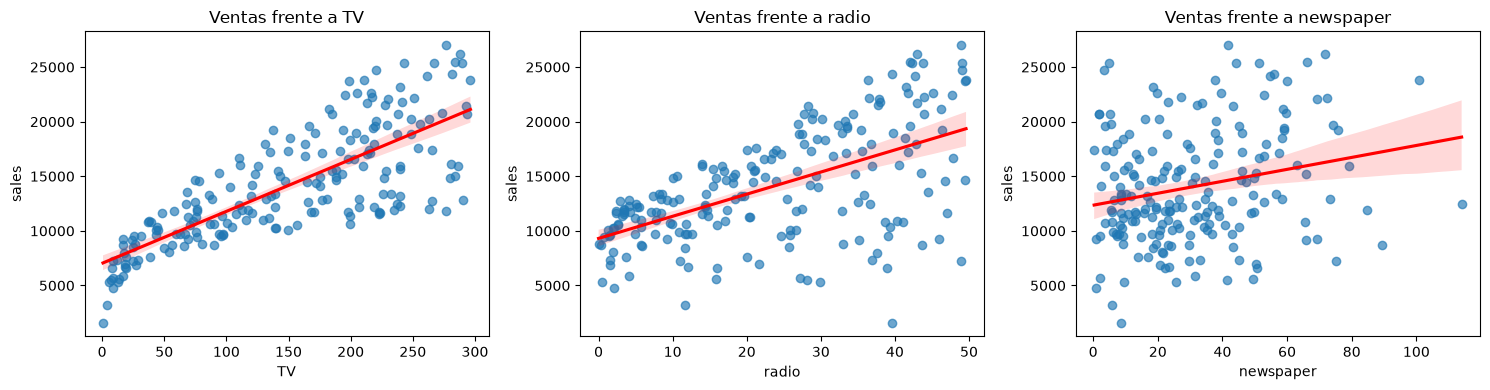

In [28]:
variables = ["TV", "radio", "newspaper"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, variable in zip(axes, variables):
    sns.regplot(
        data=df,
        x=variable,
        y="sales",
        ax=ax,
        scatter_kws={"alpha": 0.65},
        line_kws={"color": "red"}
    )
    ax.set_title(f"Ventas frente a {variable}")

plt.tight_layout()
plt.show()

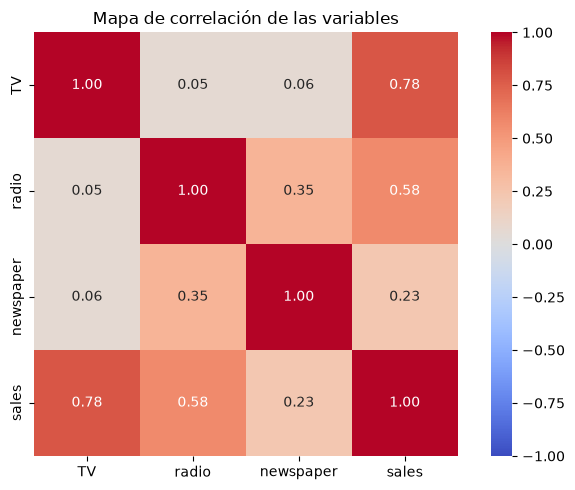

In [29]:
correlaciones = df.corr(numeric_only=True)

plt.figure(figsize=(7, 5))
sns.heatmap(
    correlaciones,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    square=True
)
plt.title("Mapa de correlación de las variables")
plt.tight_layout()
plt.show()

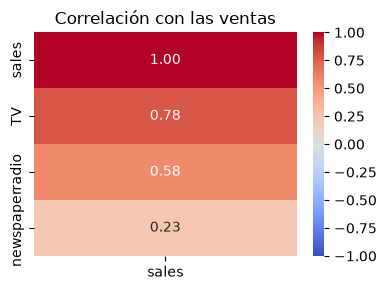

In [30]:
corr_sales = correlaciones[["sales"]].sort_values("sales", ascending=False)

plt.figure(figsize=(4, 3))
sns.heatmap(
    corr_sales,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)
plt.title("Correlación con las ventas")
plt.tight_layout()
plt.show()

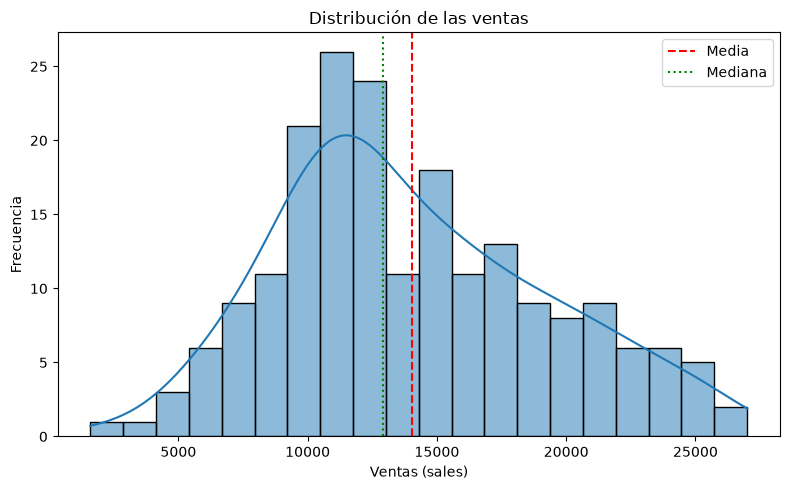

count      200.000000
mean     14022.500000
std       5217.456566
min       1600.000000
25%      10375.000000
50%      12900.000000
75%      17400.000000
max      27000.000000
Name: sales, dtype: float64

In [31]:
plt.figure(figsize=(8, 5))
sns.histplot(df["sales"], bins=20, kde=True)
plt.axvline(df["sales"].mean(), color="red", linestyle="--", label="Media")
plt.axvline(df["sales"].median(), color="green", linestyle=":", label="Mediana")
plt.xlabel("Ventas (sales)")
plt.ylabel("Frecuencia")
plt.title("Distribución de las ventas")
plt.legend()
plt.tight_layout()
plt.show()

display(df["sales"].describe())

## Modelado

In [36]:
# Manipulación datasetimport numpy as np
import pandas as pd

from sklearn.model_selection import (
    train_test_split,
    KFold,
    GridSearchCV,
    cross_val_score
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

X = df[["TV", "radio", "newspaper"]]
y = df["sales"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Entrenamiento:", X_train.shape, y_train.shape)
print("Prueba:", X_test.shape, y_test.shape)

# Los mismos pliegues para comparar los modelos de forma consistente
cv = KFold(n_splits=5, shuffle=True, random_state=42)

Entrenamiento: (160, 3) (160,)
Prueba: (40, 3) (40,)


In [37]:
def evaluar_modelo(nombre, modelo):
    predicciones = modelo.predict(X_test)

    return {
        "modelo": nombre,
        "RMSE_test": mean_squared_error(y_test, predicciones) ** 0.5,
        "MAE_test": mean_absolute_error(y_test, predicciones),
        "R2_test": r2_score(y_test, predicciones)
    }

In [38]:
modelo_dummy = DummyRegressor(strategy="mean")
modelo_dummy.fit(X_train, y_train)

modelo_lineal = make_pipeline(
    StandardScaler(),
    LinearRegression()
)

modelo_lineal.fit(X_train, y_train)

rmse_cv_lineal = -cross_val_score(
    modelo_lineal,
    X_train,
    y_train,
    cv=cv,
    scoring="neg_root_mean_squared_error"
).mean()

resultados = [
    {
        "modelo": "Dummy (media)",
        "RMSE_CV": np.nan,
        **evaluar_modelo("Dummy (media)", modelo_dummy)
    },
    {
        "modelo": "Regresión lineal",
        "RMSE_CV": rmse_cv_lineal,
        **evaluar_modelo("Regresión lineal", modelo_lineal)
    }
]

In [39]:
alphas = np.logspace(-4, 3, 50)

configuracion = {
    "Ridge": (
        make_pipeline(StandardScaler(), Ridge()),
        {"ridge__alpha": alphas}
    ),
    "Lasso": (
        make_pipeline(StandardScaler(), Lasso(max_iter=100_000)),
        {"lasso__alpha": alphas}
    ),
    "ElasticNet": (
        make_pipeline(StandardScaler(), ElasticNet(max_iter=100_000)),
        {
            "elasticnet__alpha": alphas,
            "elasticnet__l1_ratio": [0.1, 0.5, 0.9, 0.95, 0.99]
        }
    )
}

busquedas = {}

for nombre, (pipeline, parametros) in configuracion.items():
    busqueda = GridSearchCV(
        estimator=pipeline,
        param_grid=parametros,
        cv=cv,
        scoring="neg_root_mean_squared_error",
        n_jobs=-1
    )
    busqueda.fit(X_train, y_train)

    busquedas[nombre] = busqueda

    resultados.append({
        "modelo": nombre,
        "RMSE_CV": -busqueda.best_score_,
        **evaluar_modelo(nombre, busqueda.best_estimator_)
    })

resultados_df = (
    pd.DataFrame(resultados)
    .drop(columns=["modelo"])
    .join(pd.DataFrame(resultados)[["modelo"]])
    [["modelo", "RMSE_CV", "RMSE_test", "MAE_test", "R2_test"]]
    .sort_values("RMSE_CV", na_position="last")
)

display(resultados_df)

for nombre, busqueda in busquedas.items():
    print(f"{nombre}: mejores parámetros = {busqueda.best_params_}")

,modelo,RMSE_CV,RMSE_test,MAE_test,R2_test
3,Lasso,1666.911448,1785.187250,1455.638189,0.899033
1,Regresión lineal,1675.809832,1781.599662,1460.756717,0.899438
2,Ridge,1675.809916,1781.600202,1460.757075,0.899438
4,ElasticNet,1675.809921,1781.600526,1460.757272,0.899438
0,Dummy (media),NaN,5631.496249,4962.500000,-0.004757


Ridge: mejores parámetros = {'ridge__alpha': np.float64(0.0001)}
Lasso: mejores parámetros = {'lasso__alpha': np.float64(71.96856730011514)}
ElasticNet: mejores parámetros = {'elasticnet__alpha': np.float64(0.0001), 'elasticnet__l1_ratio': 0.99}


In [40]:
alpha_inicial = busquedas["Lasso"].best_params_["lasso__alpha"]
alphas_refinados = np.linspace(
    max(0.001, alpha_inicial * 0.75),
    alpha_inicial * 1.25,
    101
)

busqueda_lasso_refinada = GridSearchCV(
    estimator=make_pipeline(
        StandardScaler(),
        Lasso(max_iter=100_000)
    ),
    param_grid={"lasso__alpha": alphas_refinados},
    cv=cv,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

busqueda_lasso_refinada.fit(X_train, y_train)
modelo_lasso_final = busqueda_lasso_refinada.best_estimator_

print("Mejor alpha refinado:", busqueda_lasso_refinada.best_params_)
print("RMSE de validación cruzada:", -busqueda_lasso_refinada.best_score_)
print("Métricas de prueba:", evaluar_modelo("Lasso refinado", modelo_lasso_final))

Mejor alpha refinado: {'lasso__alpha': np.float64(78.80558119362608)}
RMSE de validación cruzada: 1666.4814920346435
Métricas de prueba: {'modelo': 'Lasso refinado', 'RMSE_test': 1786.1474068940415, 'MAE_test': 1456.3512355098046, 'R2_test': 0.8989239760078236}


In [41]:
mejor_nombre = resultados_df.iloc[0]["modelo"]

if mejor_nombre == "Lasso":
    modelo_final = modelo_lasso_final
else:
    modelo_final = busquedas[mejor_nombre].best_estimator_

escalador = modelo_final.named_steps["standardscaler"]
regresor = modelo_final.steps[-1][1]

coeficientes = regresor.coef_ / escalador.scale_
intercepto = regresor.intercept_ - np.dot(
    regresor.coef_,
    escalador.mean_ / escalador.scale_
)

print("Modelo elegido:", mejor_nombre)
print(f"Intercepto: {intercepto:.2f}")
print(pd.Series(coeficientes, index=X.columns).round(2))

Modelo elegido: Lasso
Intercepto: 3277.46
TV            43.84
radio        185.60
newspaper      0.00
dtype: float64


### Modelos Polinómicos

In [42]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.model_selection import GridSearchCV, cross_val_score
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np
import pandas as pd

# Solo para inspeccionar las columnas generadas
poly2 = PolynomialFeatures(degree=2, include_bias=False)
X_train_poly2 = poly2.fit_transform(X_train)

nombres_poly2 = poly2.get_feature_names_out(X_train.columns)
df_poly2 = pd.DataFrame(X_train_poly2, columns=nombres_poly2, index=X_train.index)

display(df_poly2.head())
print("Número de variables originales:", X_train.shape[1])
print("Número de variables polinómicas de grado 2:", df_poly2.shape[1])

,TV,radio,newspaper,TV^2,TV radio,TV newspaper,radio^2,radio newspaper,newspaper^2
79,116.0,7.7,23.1,13456.00,893.20,2679.60,59.29,177.87,533.61
197,177.0,9.3,6.4,31329.00,1646.10,1132.80,86.49,59.52,40.96
38,43.1,26.7,35.1,1857.61,1150.77,1512.81,712.89,937.17,1232.01
24,62.3,12.6,18.3,3881.29,784.98,1140.09,158.76,230.58,334.89
122,224.0,2.4,15.6,50176.00,537.60,3494.40,5.76,37.44,243.36


Número de variables originales: 3
Número de variables polinómicas de grado 2: 9


In [43]:
def metricas_test(nombre, modelo):
    pred = modelo.predict(X_test)
    return {
        "modelo": nombre,
        "RMSE_test": mean_squared_error(y_test, pred) ** 0.5,
        "MAE_test": mean_absolute_error(y_test, pred),
        "R2_test": r2_score(y_test, pred)
    }

resultados_poly_sin_reg = []
candidatos_poly = []

for grado in [1, 2, 3, 4]:
    modelo = make_pipeline(
        PolynomialFeatures(degree=grado, include_bias=False),
        StandardScaler(),
        LinearRegression()
    )

    rmse_cv = -cross_val_score(
        modelo,
        X_train,
        y_train,
        cv=cv,
        scoring="neg_root_mean_squared_error"
    ).mean()

    modelo.fit(X_train, y_train)

    fila = {
        "modelo": f"Polinómico grado {grado} sin regularización",
        "grado": grado,
        "RMSE_CV": rmse_cv,
        **metricas_test(f"Grado {grado}", modelo)
    }
    resultados_poly_sin_reg.append(fila)
    candidatos_poly.append((fila, modelo))

display(
    pd.DataFrame(resultados_poly_sin_reg)
    .sort_values("RMSE_CV")
)

,modelo,grado,RMSE_CV,RMSE_test,MAE_test,R2_test
1,Grado 2,2,675.898450,642.580912,526.179444,0.986918
2,Grado 3,3,682.030842,542.741568,388.681705,0.990667
3,Grado 4,4,868.077829,786.098670,544.250004,0.980422
0,Grado 1,1,1675.809832,1781.599662,1460.756717,0.899438


In [44]:
alphas = np.logspace(-3, 3, 20)

configuracion_poly = {
    "Poly-Ridge": (
        make_pipeline(
            PolynomialFeatures(include_bias=False),
            StandardScaler(),
            Ridge()
        ),
        {
            "polynomialfeatures__degree": [1, 2, 3],
            "ridge__alpha": alphas
        }
    ),
    "Poly-Lasso": (
        make_pipeline(
            PolynomialFeatures(include_bias=False),
            StandardScaler(),
            Lasso(max_iter=100_000)
        ),
        {
            "polynomialfeatures__degree": [1, 2, 3],
            "lasso__alpha": alphas
        }
    ),
    "Poly-ElasticNet": (
        make_pipeline(
            PolynomialFeatures(include_bias=False),
            StandardScaler(),
            ElasticNet(max_iter=100_000)
        ),
        {
            "polynomialfeatures__degree": [1, 2, 3],
            "elasticnet__alpha": alphas,
            "elasticnet__l1_ratio": [0.1, 0.5, 0.9]
        }
    )
}

busquedas_poly = {}
resultados_poly_reg = []

for nombre, (pipeline, parametros) in configuracion_poly.items():
    busqueda = GridSearchCV(
        estimator=pipeline,
        param_grid=parametros,
        cv=cv,
        scoring="neg_root_mean_squared_error",
        n_jobs=-1
    )
    busqueda.fit(X_train, y_train)
    busquedas_poly[nombre] = busqueda

    modelo = busqueda.best_estimator_
    grado = busqueda.best_params_["polynomialfeatures__degree"]

    fila = {
        "modelo": nombre,
        "grado": grado,
        "RMSE_CV": -busqueda.best_score_,
        **metricas_test(nombre, modelo),
        "mejores_parámetros": busqueda.best_params_
    }
    resultados_poly_reg.append(fila)
    candidatos_poly.append((fila, modelo))

display(
    pd.DataFrame(resultados_poly_reg)
    .sort_values("RMSE_CV")
)

,modelo,grado,RMSE_CV,RMSE_test,MAE_test,R2_test,mejores_parámetros
1,Poly-Lasso,3,583.032310,507.285674,392.623257,0.991847,"{'lasso__alpha': 2.976351441631316, 'polynomia..."
0,Poly-Ridge,3,640.863107,584.303267,451.003926,0.989183,"{'polynomialfeatures__degree': 3, 'ridge__alph..."
2,Poly-ElasticNet,3,641.618376,585.260571,452.085426,0.989148,"{'elasticnet__alpha': 0.001, 'elasticnet__l1_r..."


In [45]:
comparacion_poly = pd.concat(
    [
        pd.DataFrame(resultados_poly_sin_reg),
        pd.DataFrame(resultados_poly_reg)
    ],
    ignore_index=True,
    sort=False
).sort_values("RMSE_CV")

display(
    comparacion_poly[
        ["modelo", "grado", "RMSE_CV", "RMSE_test", "MAE_test", "R2_test"]
    ]
)

mejor_fila, modelo_poly_final = min(
    candidatos_poly,
    key=lambda candidato: candidato[0]["RMSE_CV"]
)

print("Mejor modelo según validación cruzada:")
print(mejor_fila)

,modelo,grado,RMSE_CV,RMSE_test,MAE_test,R2_test
5,Poly-Lasso,3,583.032310,507.285674,392.623257,0.991847
4,Poly-Ridge,3,640.863107,584.303267,451.003926,0.989183
6,Poly-ElasticNet,3,641.618376,585.260571,452.085426,0.989148
1,Grado 2,2,675.898450,642.580912,526.179444,0.986918
2,Grado 3,3,682.030842,542.741568,388.681705,0.990667
3,Grado 4,4,868.077829,786.098670,544.250004,0.980422
0,Grado 1,1,1675.809832,1781.599662,1460.756717,0.899438


Mejor modelo según validación cruzada:
{'modelo': 'Poly-Lasso', 'grado': 3, 'RMSE_CV': np.float64(583.032310087845), 'RMSE_test': 507.28567437828264, 'MAE_test': 392.62325700930205, 'R2_test': 0.99184697542784, 'mejores_parámetros': {'lasso__alpha': np.float64(2.976351441631316), 'polynomialfeatures__degree': 3}}


In [46]:
polynomial = modelo_poly_final.named_steps["polynomialfeatures"]
scaler = modelo_poly_final.named_steps["standardscaler"]
regressor = modelo_poly_final.steps[-1][1]

nombres = polynomial.get_feature_names_out(X_train.columns)
coef_originales = regressor.coef_ / scaler.scale_
intercepto_original = regressor.intercept_ - np.dot(
    regressor.coef_,
    scaler.mean_ / scaler.scale_
)

terminos = [
    f"{coef:+.3f}·{nombre}"
    for nombre, coef in zip(nombres, coef_originales)
    if abs(coef) > 1e-8
]

print(f"sales = {intercepto_original:.3f} " + " ".join(terminos))

sales = 4371.089 +72.996·TV +25.915·radio +14.945·newspaper -0.290·TV^2 +1.129·TV radio -0.075·TV newspaper +0.002·radio newspaper +0.000·TV^3 -0.000·TV^2 radio +0.000·TV^2 newspaper +0.001·TV radio^2 +0.000·TV newspaper^2


## Resultados

1. Resultados del análisis exploratorio
El conjunto tiene 200 observaciones y tres variables de inversión (TV, radio, newspaper), además de las ventas (sales). Las correlaciones con las ventas son:

Variable y Correlación con Sales

TV	0,782

radio	0,576

newspaper	0,228


TV muestra la asociación lineal más fuerte con las ventas; la de periódicos es bastante más débil. La media de ventas es aproximadamente 14.022,5 y la mediana 12.900, ambas en las unidades del archivo.

2. Regresión lineal y modelos regularizados

Modelo	| RMSE validación cruzada | RMSE prueba	| MAE prueba |	R² prueba

Regresión lineal	| 1.675,81	| 1.781,60	| 1.460,76	| 0,899

Ridge	| 1.675,81	| 1.781,60	| 1.460,76	| 0,899

Lasso	| 1.666,91	| 1.785,19	| 1.455,64	| 0,899

ElasticNet	| 1.675,81	| 1.781,60	| 1.460,76	| 0,899

En validación cruzada, Lasso obtiene el menor RMSE, aunque en el conjunto de prueba su RMSE es ligeramente mayor que el de la regresión lineal. Las diferencias entre estos modelos son pequeñas: en este ajuste, regularizar no mejora claramente el resultado de prueba.

3. Regresión polinómica sin regularización

Grado |	RMSE validación cruzada |RMSE prueba |	MAE prueba	| R² prueba

1-	1.675,81 | 1.781,60	| 1.460,76	| 0,899

2-	675,90	| 642,58	| 526,18	| 0,987

3-	682,03	| 542,74	| 388,68	| 0,991

4-	868,08	| 786,10	| 544,25	| 0,980

Los grados 2 y 3 mejoran mucho respecto al modelo lineal. Sin embargo, según la validación cruzada, el grado 2 es ligeramente mejor que el grado 3. El grado 4 empeora, lo que puede indicar que añadir complejidad no siempre ayuda y puede aumentar el sobreajuste.

4. Modelos polinómicos regularizados
Modelo	Grado elegido	RMSE validación cruzada	RMSE prueba	MAE prueba	R² prueba
Ridge polinómico	3	640,86	584,30	451,00	0,989
Lasso polinómico	3	583,03	507,29	392,62	0,992
ElasticNet polinómico	3	641,62	585,26	452,09	0,989
Lasso polinómico de grado 3 es el mejor de los modelos comparados según el RMSE de validación cruzada y también obtiene el mejor resultado en el conjunto de prueba. Su R² de prueba es aproximadamente 0,992.

En la escala de ventas del archivo, su RMSE de prueba es de unas 507 unidades. Es una mejora notable frente al RMSE de prueba de aproximadamente 1.782 de la regresión lineal.

5. Fórmula e interpretación del modelo elegido
La fórmula aproximada de Lasso polinómico de grado 3, expresada con los coeficientes en las unidades originales, es:

Algunos términos tienen coeficiente cero por la regularización Lasso; se han omitido de la fórmula. En este modelo, el efecto de subir la inversión en un punto no es constante: depende de los valores actuales de TV, radio y periódicos, debido a las potencias y a las interacciones. Los coeficientes describen asociaciones del modelo, no demuestran efectos causales.

Conclusión y cautelas
Para estos datos y esta partición, el modelo con mejor resultado es Lasso polinómico de grado 3.
La mejora respecto a los modelos lineales es grande en esta evaluación, pero conviene confirmarla con otras particiones o validación cruzada repetida.
El archivo no contiene fechas. La evaluación aleatoria mide el rendimiento sobre observaciones similares a las disponibles, pero no valida por sí sola una predicción de meses futuros. Para ese uso harían falta datos temporales y una separación cronológica entre entrenamiento y prueba.
Las unidades monetarias o de inversión no están documentadas en el archivo; las cifras deben interpretarse en las unidades registradas, no asumirse como euros.